In [1]:
import numpy as np
import torch
import os,glob
from collections import OrderedDict
from torchvision import datasets, transforms
from attrdict import AttrDict


from train_v3_base import  (setup_randomness,
                           setup_dataset,
                           setup_model,
                           #eval_trainedmodel,
                    )


In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"   # see issue #152
os.environ["CUDA_VISIBLE_DEVICES"]="0"

In [3]:
trainset,contexset,oodset='cifar10', 'cifar100','svhn'
results_path = './results/{}_{}'.format(trainset,contexset)
results_path_list = sorted(glob.glob(results_path + '/*/'))

results_path

'./results/cifar10_cifar100'

In [4]:
results_path_list.sort(key=os.path.getmtime)

#results_path_list = results_path_list[-1:]
results_path_list

['./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet18/']

In [5]:
from evaluate_v2 import (ts,
                         apply_t,
                         get_acc,
                         get_ll,
                         get_ece,
                         get_ood_auroc,           
                         get_entropy,              
                         )

from torch.nn.functional import log_softmax
from sklearn.model_selection import KFold
from scipy.optimize import minimize
from collections import OrderedDict




def eval_trainedmodel(dataloader, model,q_params = None , nfsample=1, topk=3, configs=None):
    assert q_params is not None
    pred_list,label_list,logit_list = [],[],[]    

    model.eval()    
    with torch.no_grad():
        for i, (x, y) in enumerate(dataloader):    
            # predict class            
            outs = model.predict_eval(x.cuda(), nfsample=nfsample, topk=topk)                     

            # compute performance
            logit_list.append(outs.logits.cpu())
            pred_list.append(outs.pred.cpu())
            label_list.append(y.cpu())

            torch.cuda.empty_cache() 
    
    pred_list = torch.cat(pred_list,dim=0)    
    label_list = torch.cat(label_list,dim=0)    
    logit_list = torch.cat(logit_list,dim=1)    
        
    # evaluate model
    outs = AttrDict()
    outs.pred_list = pred_list
    outs.label_list = label_list    
    outs.logit_list = logit_list.transpose(1,0)
    return outs    



def _compute_diversity_ratio(outs , digits=3):
    yhat = outs.logit_list.max(dim=-1)[1]
    nfsample = yhat.shape[-1]

    static_list = []
    for i_yhat in yhat:
        i_yhat_unique,i_yhat_unique_cnt = i_yhat.unique(return_counts=True)
        top1_cnt = i_yhat_unique_cnt.topk(1).values.item()
        majority_cnt = top1_cnt
        not_majority_cnt = nfsample - top1_cnt


        static_list.append( (majority_cnt/nfsample, not_majority_cnt/ nfsample , not_majority_cnt/ majority_cnt) )  #( majority_cnt/nfsample,       not_majority_cnt/ nfsample ,   not_majority_cnt/ majority_cnt )
    
    static_list = np.array(static_list).round(3)
    return static_list.mean(axis=0).round(digits), ((1/np.sqrt(nfsample))*static_list.std(axis=0)).round(digits)

# With Calibration

## calibaration revision

In [6]:
from attrdict import AttrDict
configs = AttrDict( dataset = AttrDict( trainset = trainset, contextset = contexset, oodset = [oodset] ),
                    train   = AttrDict( nbatch = 128 ),
                    exp     = AttrDict( seeds = '1111')
                )    
trainloader,valloader,testloader,contextloader,oodlist_loader = setup_dataset(configs,fortrain=False) 
oodloader_v1 = oodlist_loader[0]

#configs
#setup_randomness(i_th_saved['configs'].exp.seeds)

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
Using downloaded and verified file: /home/becre1776/Datasets/SVHN/train_32x32.mat
Using downloaded and verified file: /home/becre1776/Datasets/SVHN/test_32x32.mat


In [7]:
from evaluate_v2 import (ts,
                         apply_t,
                         get_acc,
                         get_ll,
                         get_ece,
                         get_ood_auroc,      
                         get_ood_auroc2,     
                         get_entropy,              
                         )


def get_results_from_outs(outs,outs_ood1,n_runs=5,n_splits=2,digits=3):
    
    log_preds, targets  = (outs.pred_list.log()).cpu().data.numpy(), outs.label_list.cpu().data.numpy()
    log_ood1_preds, targets_ood1 = (outs_ood1.pred_list.log()).cpu().data.numpy(), outs_ood1.label_list.cpu().data.numpy()
        
    # ------------------------------------------------
    # evaluate acc,nll, and, ece
    # ------------------------------------------------        
    acc_runs,nll_runs,ece_runs,aucroc1,aucroc2 = [],[],[],[],[]
    indent1,indent2 = [],[]        
    outdent1,outdent2 = [],[]
    
    for runs in range(n_runs):
        for i, (tr_idx, te_idx) in enumerate(KFold(n_splits=n_splits, shuffle=True).split(log_preds)):
            train_t = ts(log_preds[tr_idx], targets[tr_idx])
            test_lp = apply_t(log_preds[te_idx], train_t)                    
            acc_runs.append( get_acc(np.exp(test_lp), targets[te_idx] ) )
            nll_runs.append( -get_ll(np.exp(test_lp), targets[te_idx]) )
            ece_runs.append( get_ece(np.exp(test_lp), targets[te_idx]) )       


            #test_lp = apply_t(log_preds[te_idx], train_t)                  
            test_lp_ood = apply_t(log_ood1_preds[te_idx], train_t)  
            
            test_lp_in_out = np.concatenate([test_lp,test_lp_ood],axis=0)
            #labels_in_out = np.array(list(np.zeros( test_lp.shape[0] )) + list(np.ones(test_lp_ood.shape[0] )))
            ood_labels = np.array(  list(np.zeros( test_lp.shape[0] )) + list(np.ones(test_lp_ood.shape[0] ) )  )

            
            # aucroc1.append( get_ood_auroc(np.exp(test_full1_lp),[],targets_fullood1[te_idx] ) )       
            aucroc1.append(  get_ood_auroc2(np.exp(test_lp_in_out ), ood_labels  ) )       
                            
            tmp_indent1 =  get_entropy( np.exp(test_lp) )
            tmp_outdent1 = get_entropy( np.exp(test_lp_ood) )
            indent1.append(  tmp_indent1  )
            outdent1.append( tmp_outdent1 )                
            
            
    acc,nll,ece = np.mean(acc_runs).round(digits),np.mean(nll_runs).round(digits),np.mean(ece_runs).round(digits)                                   
    aucroc1 = np.mean(aucroc1).round(digits)
    indent1,outdent1 = np.mean(indent1).round(digits),np.mean(outdent1).round(digits)
    
    
    # evaluate functional diversity
    fdiv_in = _compute_diversity_ratio(outs , digits=3)
    fdiv_out = _compute_diversity_ratio(outs_ood1 , digits=3)

    # ratio = (# of majority) # sample function   
    fdivin = fdiv_in[0][1], fdiv_in[1][1]
    fdivout = fdiv_out[0][1], fdiv_out[1][1]
    
    # ratio = (# sample function - # of majority) / # of majority
    rfdivin = fdiv_in[0][2],fdiv_in[1][2]      
    rfdivout = fdiv_out[0][2],fdiv_out[1][2]
    
    return acc,nll,ece,aucroc1,indent1,outdent1,fdivin,fdivout,rfdivin,rfdivout



In [9]:
import copy
from torch.nn.functional import log_softmax
from sklearn.model_selection import KFold
from scipy.optimize import minimize
from collections import OrderedDict
from attrdict import AttrDict

def _get_modelspec_from_configs(configs):
    model_spec = configs.model.modelname
    model_spec += '_logstd{}'.format(configs.model.scalelogstd)    
    model_spec += '_pstdout{}'.format(configs.model.priorstdout)
    model_spec += '_nfs{}'.format(configs.train.nfsample)
    model_spec += '_temppeak{}'.format(configs.model.temppeak) if 'temppeak' in configs.model.keys() else '_temppeak{}'.format(.5)   
    model_spec += '_reglam{}'.format(configs.train.reglambda)
    model_spec += '_topk{}'.format(configs.train.topk) if 'topk' in configs.train.keys() else '_topk{}'.format(10)
    model_spec += '_nepr{}'.format(configs.train.nepochratio) if 'nepochratio' in configs.train.keys() else '_nepr{}'.format(0)
    model_spec += '_lt{}'.format(configs.train.losstype) if 'losstype' in configs.train.keys() else '_lt{}'.format('elbo')
    model_spec += '_mixct{}'.format(configs.train.mixcontext) if 'mixcontext' in configs.train.keys() else  '_mixct{}'.format(False)
    model_spec += '_mixself{}'.format(configs.train.mixself) if 'mixself' in configs.train.keys() else  '_mixself{}'.format(False)
    model_spec += '_mixalpha{}'.format(configs.train.mixalpha) if 'mixalpha' in configs.train.keys() else  '_mixmixalpha{}'.format(0.0)
    model_spec += '_paramtrace{}'.format(configs.train.paramtrace) if 'paramtrace' in configs.train.keys() else  '_paramtrace{}'.format(0)
        
    return model_spec

def update_keys_oddset(configs:AttrDict,ood_dict:dict):
    outs = {**dict(configs.dataset) , **ood_dict}
    configs.dataset = {}
    configs.dataset = AttrDict(outs)
    return copy.deepcopy(configs)



In [10]:
singlesample_model_list = ['resnet20','spresnet20']
n_runs,n_splits,digits = 5,2,3


metric_dict = OrderedDict()
#for current_path in results_path_list:
for current_path in results_path_list:

    metric_dict[current_path.split('/')[-1]] = AttrDict()
    

    current_path_list = sorted(glob.glob(current_path + '/*.pth'))    
    
    if len(current_path_list) > 0:
        #current_path_list
        for i_th_file in current_path_list:
            i_th_saved = torch.load(i_th_file)
            ## get model spec     
            modelspec = _get_modelspec_from_configs(i_th_saved['configs'])

            
            ## edit configs for oodsets        
            # setup randomness
            setup_randomness(i_th_saved['configs'].exp.seeds)
            
            #model,optimizer,scheduler,loss_fn = setup_model(i_th_saved['configs'])
            model,optimizer,scheduler = setup_model(i_th_saved['configs'])
            

            # load the saved parameters on model
            model.load_state_dict(i_th_saved['state_dict'])

        
                        
            ## evaluate model with i_th_saved['configs'].train.nfsample      
            #nfsample=10
            #nfsample=50
            #nfsample=500        
            
            # map inference --> nfsample = 1
            if i_th_saved['configs'].model.modelname in singlesample_model_list:
                nfsample_list = [1]
            else:
                #nfsample_list = [2,5,10,50,100]                        
                nfsample_list = [3,10,100]        
            
            for nfsample in nfsample_list:
                topk = i_th_saved['configs'].train.topk
                outs =      eval_trainedmodel(testloader, model, q_params = list(model.parameters())   ,topk=topk , nfsample = nfsample)        
                outs_ood1 = eval_trainedmodel(oodloader_v1, model, q_params = list(model.parameters()) ,topk=topk , nfsample = nfsample)       
                
                
            
                acc,nll,ece,aucroc1,indent1,outdent1,fdivin,fdivout,rfdivin,rfdivout = get_results_from_outs(outs,outs_ood1,n_runs=n_runs,n_splits=n_splits,digits=digits)
            
            
            
                # set
                if modelspec + '_nfs{}'.format(nfsample) not in metric_dict.keys():
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)] = OrderedDict()
                
            
                #if 'acc' not in metric_dict[modelspec + '_nfs{}'.format(nfsample)].keys():
                if  len(metric_dict[modelspec + '_nfs{}'.format(nfsample)].keys()) == 0 :                
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['acc'] = [acc]
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['nll'] = [nll]
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['ece'] = [ece]
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['aucroc1'] = [aucroc1]

                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['indent1'] = [indent1]                       
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['outdent1'] = [outdent1]            

                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['fdivin'] = [fdivin]                       
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['fdivout'] = [fdivout]                       
                    
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['rfdivin'] = [rfdivin]                       
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['rfdivout'] = [rfdivout]                       
                    
                else:
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['acc'].append(acc)
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['nll'].append(nll)
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['ece'].append(ece)
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['aucroc1'].append(aucroc1)

                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['indent1'].append(indent1)                       
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['outdent1'].append(outdent1)            

                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['fdivin'].append(fdivin)                       
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['fdivout'].append(fdivout)                       
                    
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['rfdivin'].append(rfdivin)                       
                    metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['rfdivout'].append(rfdivout)                       
            
            
        
        torch.cuda.empty_cache()
    else:
        print('current_path_list is empty')
    
metric_dict_calibrated = copy.deepcopy(metric_dict)
    

get deep model: bmafbresnet18
temppeak: 0.75


/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:245: UserWarning: nn.init.kaiming_normal is now deprecated in favor of nn.init.kaiming_normal_.
  init.kaiming_normal(m.weight, mode='fan_out')
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:255: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.weight, 1)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:256: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:258: UserWarning: nn.init.normal is now deprecated in favor of nn.init.normal_.
  init.normal(m.weight, std=1e-3)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:261: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)


get deep model: bmafbresnet18
temppeak: 0.75


/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:245: UserWarning: nn.init.kaiming_normal is now deprecated in favor of nn.init.kaiming_normal_.
  init.kaiming_normal(m.weight, mode='fan_out')
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:255: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.weight, 1)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:256: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:258: UserWarning: nn.init.normal is now deprecated in favor of nn.init.normal_.
  init.normal(m.weight, std=1e-3)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:261: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)


get deep model: fbresnet18


/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:245: UserWarning: nn.init.kaiming_normal is now deprecated in favor of nn.init.kaiming_normal_.
  init.kaiming_normal(m.weight, mode='fan_out')
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:255: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.weight, 1)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:256: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:258: UserWarning: nn.init.normal is now deprecated in favor of nn.init.normal_.
  init.normal(m.weight, std=1e-3)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:261: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)


get deep model: fbresnet18


/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:245: UserWarning: nn.init.kaiming_normal is now deprecated in favor of nn.init.kaiming_normal_.
  init.kaiming_normal(m.weight, mode='fan_out')
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:255: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.weight, 1)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:256: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:258: UserWarning: nn.init.normal is now deprecated in favor of nn.init.normal_.
  init.normal(m.weight, std=1e-3)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:261: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)


## check the effectiveness of the proposed model performance 

In [11]:
from tabulate import tabulate

performance_list = ['acc','nll','ece','aucroc1','indent1','outdent1','fdivin','fdivout','rfdivin','rfdivout']
def get_tables(metric_dict,digits=3,performance_list=performance_list):

    ## metric state dict    z
    metric_static_dict = OrderedDict()
    for i_key in metric_dict:
        metric_static_dict[i_key] = AttrDict() 
        for ij_key in metric_dict[i_key]:
            
            if ij_key in performance_list:
                #metric_static_dict[i_key][ij_key] = (np.array(metric_dict[i_key][ij_key]).mean().round(digits), np.array(metric_dict[i_key][ij_key]).std().round(digits))
                nexp   = len(metric_dict[i_key][ij_key])
                mean   = np.array(metric_dict[i_key][ij_key]).mean().round(digits)
                stderr = (np.array(metric_dict[i_key][ij_key]).std()/np.sqrt(nexp)).round(digits)
                metric_static_dict[i_key][ij_key] = (mean,stderr)

    #--------------------------------
    # contents
    #--------------------------------
    table = []
    for ith_key in metric_static_dict:
        #print(ith_key)
        ith_re_key = [jth_key + '/' for jth_key in ith_key.split('_')[2:]] 
        
        ith_re_key = []
        for jth_key in ith_key.split('_')[2:]:
            #print(jth_key)
            if jth_key[:2] in ['ne','nb','ne','lr','Tm','nc']:
                pass
            else:
                ith_re_key.append(  jth_key + '/'  ) 
        
        #print(ith_re_key)
        ith_re_key = ''.join(ith_re_key)
        ith_re_values = list(metric_static_dict[ith_key].values())
        #table.append([ith_re_key] + ith_re_values)
        table.append(ith_re_values)

    #--------------------------------
    # headers
    #--------------------------------
    headers = ['modelspec'] +  list(metric_static_dict[ith_key].keys())    
    
    return metric_dict,metric_static_dict,table,headers


In [21]:
lentitle = 0
#metric_dict,metric_static_dict,table,headers = get_tables(metric_dict_calibrated)


performance_list = ['acc','nll','ece','aucroc1','indent1','outdent1','rfdivin','rfdivout']
#performance_list = ['acc','nll','ece','aucroc1','rfdivin','rfdivout']
metric_dict,metric_static_dict,table,headers = get_tables(metric_dict_calibrated,performance_list=performance_list)


nfsample_list 

#ncases=4
ncases=len(nfsample_list)
proposed,baseline = np.array(table[1:1+ncases]), np.array(table[1+ncases:2+ncases+ncases])


In [22]:
proposed

array([[[9.50000000e-01, 0.00000000e+00],
        [1.80999994e-01, 1.00000000e-03],
        [8.00000000e-03, 0.00000000e+00],
        [9.48000000e-01, 1.00000000e-03],
        [1.80999994e-01, 1.00000000e-03],
        [1.13399994e+00, 2.70000000e-02],
        [3.40000000e-02, 1.50000000e-02],
        [1.64000000e-01, 2.00000000e-02]],

       [[9.50000000e-01, 0.00000000e+00],
        [1.75999999e-01, 2.00000000e-03],
        [9.00000000e-03, 0.00000000e+00],
        [9.53000000e-01, 2.00000000e-03],
        [1.75999999e-01, 2.00000000e-03],
        [1.13199997e+00, 3.40000000e-02],
        [2.70000000e-02, 6.00000000e-03],
        [1.61000000e-01, 3.80000000e-02]],

       [[9.50000000e-01, 0.00000000e+00],
        [1.74999997e-01, 1.00000000e-03],
        [1.00000000e-02, 0.00000000e+00],
        [9.54000000e-01, 1.00000000e-03],
        [1.73999995e-01, 2.00000000e-03],
        [1.12899995e+00, 2.70000000e-02],
        [1.60000000e-02, 3.00000000e-03],
        [1.42000000e-01, 7.400

In [23]:
#proposed
nfsample_list 

[3, 10, 100]

### Inpretation of Prior constrution through MPA

In [24]:
topk=10

import math
import torch.nn.functional as F
from evaluate_v2 import (ts,
                         apply_t,
                         get_acc,
                         get_ll,
                         get_ece,
                         get_ood_auroc,      
                         get_ood_auroc2,     
                         get_entropy,              
                         )

def compute_prior_logits_from_dataloader(model,testloader,oodloader,topk=10):    
    
    def _compute_logtis_MPA(pmu,pstd):
        pi = math.pi        
        nominator   = pmu
        denominator = torch.sqrt(1 + (pi/8)*pstd**2)
        return F.softmax(nominator/denominator)
        #return nominator/denominator
        
    logits_xt_list,yt_list = [],[]
    for xt, yt in testloader:    
        p_xt = model.compute_fdist(xt.cuda(),topk=topk)[1]
        p_logit_xt = _compute_logtis_MPA(*p_xt)
        
        logits_xt_list.append(p_logit_xt.cpu().data.numpy())
        yt_list.append(yt.cpu().data.numpy())
                     
    logits_xo_list = []
    for xo, yo in oodloader:    
        p_xo = model.compute_fdist(xo.cuda(),topk=topk)[1]
        p_logit_xo = _compute_logtis_MPA(*p_xo)

        logits_xo_list.append(p_logit_xo.cpu().data.numpy())
        
    outs_xt = AttrDict()
    outs_xt.pred_list  = np.concatenate(logits_xt_list,axis=0)
    outs_xt.label_list = np.concatenate(yt_list,axis=0)
 
    outs_xo = AttrDict()
    outs_xo.pred_list  = np.concatenate(logits_xo_list,axis=0)
        
    return outs_xt,outs_xo




def get_results_from_outs_prior(outs,outs_ood1,n_runs=5,n_splits=2,digits=3):
    
    log_preds      = np.log(outs.pred_list)
    targets        = outs.label_list
    log_ood1_preds = np.log(outs_ood1.pred_list)
    
    # ------------------------------------------------
    # evaluate acc,nll, and, ece
    # ------------------------------------------------        
    acc_runs,nll_runs,ece_runs,aucroc1,aucroc2 = [],[],[],[],[]
    indent1,indent2 = [],[]        
    outdent1,outdent2 = [],[]
    
    for runs in range(n_runs):
        for i, (tr_idx, te_idx) in enumerate(KFold(n_splits=n_splits, shuffle=True).split(log_preds)):
            train_t = ts(log_preds[tr_idx], targets[tr_idx])
            test_lp = apply_t(log_preds[te_idx], train_t)                    
            acc_runs.append( get_acc(np.exp(test_lp), targets[te_idx] ) )
            nll_runs.append( -get_ll(np.exp(test_lp), targets[te_idx]) )
            ece_runs.append( get_ece(np.exp(test_lp), targets[te_idx]) )       



            #test_lp = apply_t(log_preds[te_idx], train_t)                  
            test_lp_ood = apply_t(log_ood1_preds[te_idx], train_t)  
            
            test_lp_in_out = np.concatenate([test_lp,test_lp_ood],axis=0)
            #labels_in_out = np.array(list(np.zeros( test_lp.shape[0] )) + list(np.ones(test_lp_ood.shape[0] )))
            ood_labels = np.array(  list(np.zeros( test_lp.shape[0] )) + list(np.ones(test_lp_ood.shape[0] ) )  )

            
            # aucroc1.append( get_ood_auroc(np.exp(test_full1_lp),[],targets_fullood1[te_idx] ) )       
            aucroc1.append(  get_ood_auroc2(np.exp(test_lp_in_out ), ood_labels  ) )       
                            
            tmp_indent1 =  get_entropy( np.exp(test_lp) )
            tmp_outdent1 = get_entropy( np.exp(test_lp_ood) )
            indent1.append(  tmp_indent1  )
            outdent1.append( tmp_outdent1 )                
            
            
    # ------------------------------------------------
    # evaluate acc,nll, and, ece
    # ------------------------------------------------                        
    acc,nll,ece = np.mean(acc_runs).round(digits),np.mean(nll_runs).round(digits),np.mean(ece_runs).round(digits)                                   
    aucroc1 = np.mean(aucroc1).round(digits)
    indent1,outdent1 = np.mean(indent1).round(digits),np.mean(outdent1).round(digits)
    
    return acc,nll,ece,aucroc1,indent1,outdent1
    


## get the results of the BMA prior by MPA approximation

In [25]:
current_path = results_path_list[0]
current_path_list = sorted(glob.glob(current_path + '/*.pth'))    

#current_path_list
topk=10

prior_results_list = []
for ith in range(len(current_path_list)):
    i_th_saved = torch.load(current_path_list[ith])
    ## get model spec     
    modelspec = _get_modelspec_from_configs(i_th_saved['configs'])

    ## edit configs for oodsets        
    # setup randomness
    setup_randomness(i_th_saved['configs'].exp.seeds)

    #model,optimizer,scheduler,loss_fn = setup_model(i_th_saved['configs'])
    model_1,optimizer_1,scheduler_1 = setup_model(i_th_saved['configs'])

    # load the saved parameters on model
    model_1.load_state_dict(i_th_saved['state_dict'])
    
    #np.concatenate(yt_list_1,axis=0)
    outs_xt_1,outs_xo_1                  = compute_prior_logits_from_dataloader(model_1,testloader,oodloader_v1,topk=topk)
    acc,nll,ece,aucroc1,indent1,outdent1 = get_results_from_outs_prior(outs_xt_1,outs_xo_1,n_runs=5,n_splits=2,digits=3)

    prior_results_list.append( (acc,nll,ece,aucroc1,indent1,outdent1) )
    

#acc,nll,ece,aucroc1,indent1,outdent1
digit=3
mu_prior = np.array(prior_results_list).mean(axis=0).round(digit)
std_prior = np.array(prior_results_list).std(axis=0).round(digit)

mu_prior,std_prior

get deep model: bmafbresnet18
temppeak: 0.75


/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:245: UserWarning: nn.init.kaiming_normal is now deprecated in favor of nn.init.kaiming_normal_.
  init.kaiming_normal(m.weight, mode='fan_out')
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:255: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.weight, 1)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:256: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:258: UserWarning: nn.init.normal is now deprecated in favor of nn.init.normal_.
  init.normal(m.weight, std=1e-3)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:261: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/tmp/ipykernel_649768/779295605.py:21: UserWarning: Implicit dimension choice for softmax has bee

get deep model: bmafbresnet18
temppeak: 0.75


/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:245: UserWarning: nn.init.kaiming_normal is now deprecated in favor of nn.init.kaiming_normal_.
  init.kaiming_normal(m.weight, mode='fan_out')
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:255: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.weight, 1)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:256: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:258: UserWarning: nn.init.normal is now deprecated in favor of nn.init.normal_.
  init.normal(m.weight, std=1e-3)
/home/becre1776/project_fbnn/src2_upload/models_deepnet_v3.py:261: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/tmp/ipykernel_649768/779295605.py:21: UserWarning: Implicit dimension choice for softmax has bee

(array([0.928, 0.29 , 0.02 , 0.859, 0.29 , 0.872]),
 array([0.003, 0.004, 0.001, 0.003, 0.004, 0.039]))

## Investigate the effect of the proposed infernce over varying sample functions

In [26]:
width =.35
nexp=3
alpha_=0.75
ticksiz=10
labelsiz=10
error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)



metric_name_dict = OrderedDict()
metric_name_list = ['accuracy','nll','ece','aucroc','ind-entropy','out-entropy','ind-fdiv ratio','ood-fdiv ratio']

for i, i_name in enumerate(metric_name_list):
    metric_name_dict[i] = i_name 


target_idx_list = list(metric_name_dict.keys())

target_idx_list,metric_name_dict


([0, 1, 2, 3, 4, 5, 6, 7],
 OrderedDict([(0, 'accuracy'),
              (1, 'nll'),
              (2, 'ece'),
              (3, 'aucroc'),
              (4, 'ind-entropy'),
              (5, 'out-entropy'),
              (6, 'ind-fdiv ratio'),
              (7, 'ood-fdiv ratio')]))

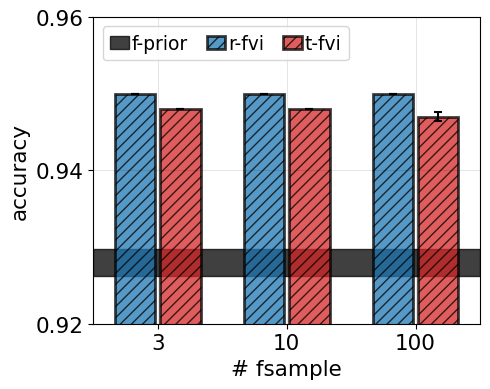

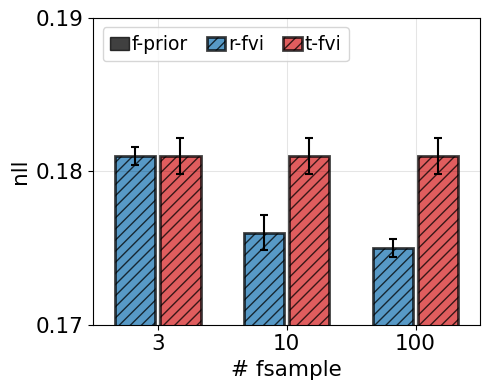

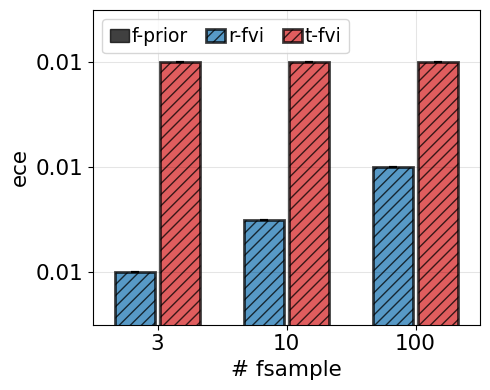

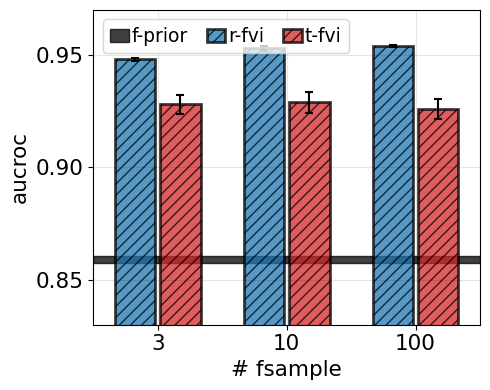

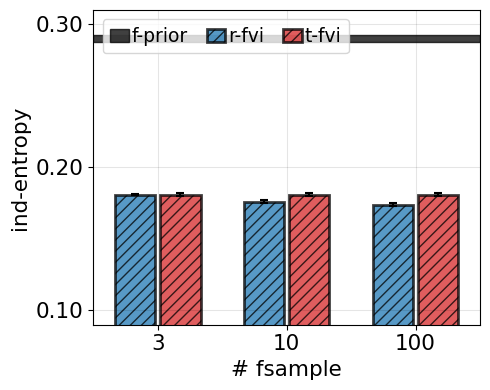

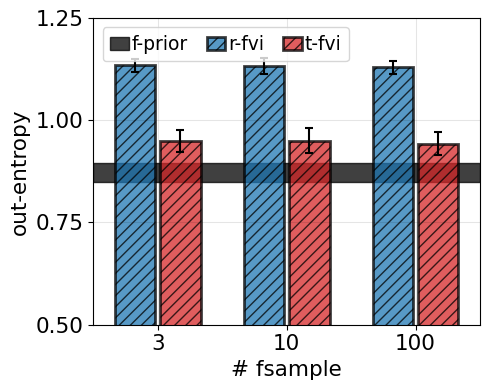

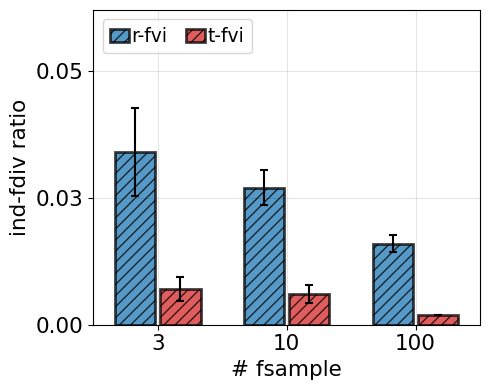

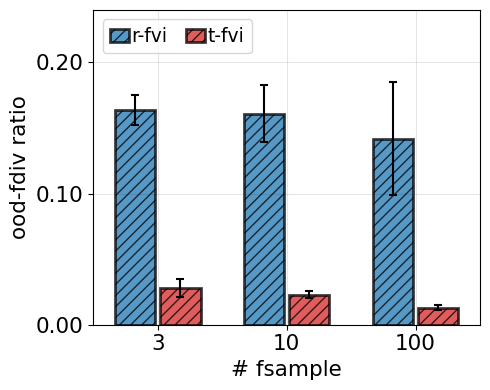

In [34]:
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.ticker import PercentFormatter,FormatStrFormatter,ScalarFormatter

        
        
for target_idx in target_idx_list:
    
    metric_name = metric_name_dict[target_idx]

    config_figs = AttrDict()
    #config_figs.figsiz = (7,4) 
    config_figs.figsiz = (5,4) 

    config_figs.nbins =100
    eps=1e-2
    config_figs.fontsiz = 15.5
    config_figs.fontsiztitle = 15.5
    config_figs.alpha= 0.66
    config_figs.alpha2= 0.33
    config_figs.range = [0-eps,2 +eps]
    config_figs.range2 = [0-eps,1 +eps]


    matplotlib.rc('xtick', labelsize=config_figs.fontsiz) 
    matplotlib.rc('ytick', labelsize=config_figs.fontsiz) 
    matplotlib.rc('axes',  labelsize=config_figs.fontsiz) 

        
    eps=2e-1   
    config_figs.xlim = [1 - 0.3 - eps, len(nfsample_list)  + 0.3 + eps] 
    config_figs.xticks = nfsample_list 

    # width=0.9


    if target_idx==0:
        config_figs.ylim = [.92,.96] 

    if target_idx==1:
        config_figs.ylim = [.170,.190] 

    if target_idx==2:
        config_figs.ylim = [.007,.013] 

    if target_idx==3:
        config_figs.ylim = [.83,.97] 

    if target_idx==4:
        config_figs.ylim = [.09,.31] 

    if target_idx==5:
        config_figs.ylim = [0.5,1.25] 

    if target_idx==6:
        config_figs.ylim = [.0,.062] 

    if target_idx==7:
        config_figs.ylim = [.0,.24] 



    
    ## get metric    
    metric_pro,metric_base = np.array([ith for ith in proposed[:,target_idx]]),np.array([ith for ith in baseline[:,target_idx]])
            
    f,axs= plt.subplots(  figsize=config_figs.figsiz )    

    ##-----------------------------------------------------
    ## proposed prior
    ##-----------------------------------------------------

    #mu,std  = metric_pro[:,0],metric_pro[:,1]
    if target_idx not in [6,7]:
        mu,std  = mu_prior[target_idx], std_prior[target_idx]
        upper_threshold = mu+std/np.sqrt(nexp)+1e-5,
        lower_threshold = mu-std/np.sqrt(nexp)-1e-5,
        axs.fill_between(config_figs.xlim,
                        upper_threshold ,
                        lower_threshold ,
                        color='black',
                        alpha=0.75,
                        label='f-prior')   



    ##-----------------------------------------------------
    ## proposed 1
    ##-----------------------------------------------------
    # results = result_dict[key1]['result_acc']
    # results = np.array(results)    
    mu,std  = metric_pro[:,0],metric_pro[:,1]
    xrange = np.arange(1,len(mu)+1 )       
    axs.bar(xrange + -0.5*width, mu , 0.9*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:blue',
        alpha=alpha_,
        edgecolor='black',                
        label='r-fvi',
    )


    ##-----------------------------------------------------
    ## basline
    ##-----------------------------------------------------
    mu2,std2 = metric_base[:,0],metric_base[:,1]
    xrange = np.arange(1,len(mu2)+1)       
    axs.bar(xrange + 0.5*width, mu2 , 0.9*width, yerr= 1*std2/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:red',
        alpha=alpha_,
        edgecolor='black',                
        label='t-fvi',
    )    

    axs.set_xticks(xrange,config_figs.xticks)
    #axs.set_yticks(config_figs.yticks)
    axs.set_xlim(config_figs.xlim)
    axs.set_ylim(config_figs.ylim)

    axs.set_xlabel('# fsample',fontsize=config_figs.fontsiz)
    axs.set_ylabel('{}'.format(metric_name),fontsize=config_figs.fontsiz)
    axs.grid(alpha=0.1,color="black")


    if target_idx==3:
        axs.set_yticks([.85,.90,.95])


    plt.gca().yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

    plt.locator_params(axis='y', nbins=3)


    # legend
    #if target_idx == 0:
    axs.legend(loc='upper left',fontsize=config_figs.fontsiz-2,ncol=3,columnspacing=1.0,handlelength=1.0,handletextpad=.15 )

    plt.tight_layout()
    plt.show()
